Optional wavelet step skipped. Install with: python -m pip install PyWavelets
STL skipped: NB01BR0006_Alkalinity__total Failed to convert value(s) to axis units: (datetime.date(1970, 1, 1), datetime.date(1970, 1, 2))
STL skipped: NB01BR0006_Aluminum Failed to convert value(s) to axis units: (datetime.date(1970, 1, 1), datetime.date(1970, 1, 2))
STL skipped: NB01BR0006_Antimony Failed to convert value(s) to axis units: (datetime.date(1970, 1, 1), datetime.date(1970, 1, 2))
STL skipped: NB01BR0006_Apparent_color Failed to convert value(s) to axis units: (datetime.date(1970, 1, 1), datetime.date(1970, 1, 2))
STL skipped: NB01BR0006_Arsenic Failed to convert value(s) to axis units: (datetime.date(1970, 1, 1), datetime.date(1970, 1, 2))
STL skipped: NB01BR0006_Barium Failed to convert value(s) to axis units: (datetime.date(1970, 1, 1), datetime.date(1970, 1, 2))
STL skipped: NB01BR0006_Beryllium Failed to convert value(s) to axis units: (datetime.date(1970, 1, 1), datetime.date(1970, 1, 2))

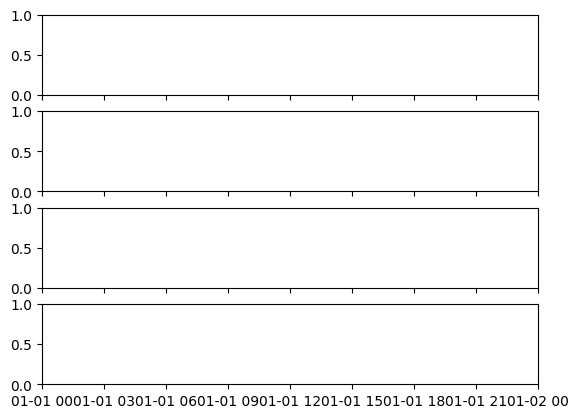

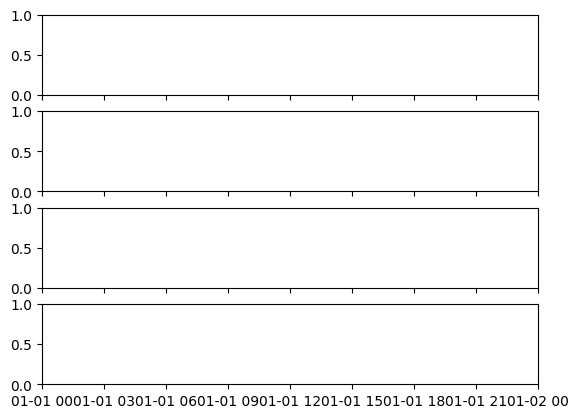

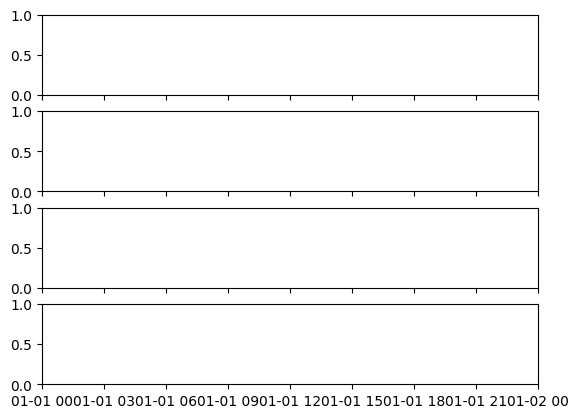

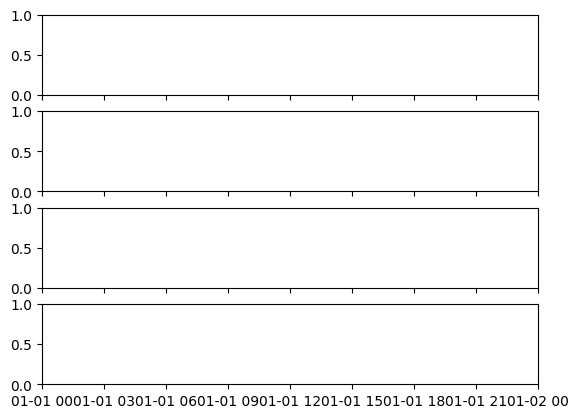

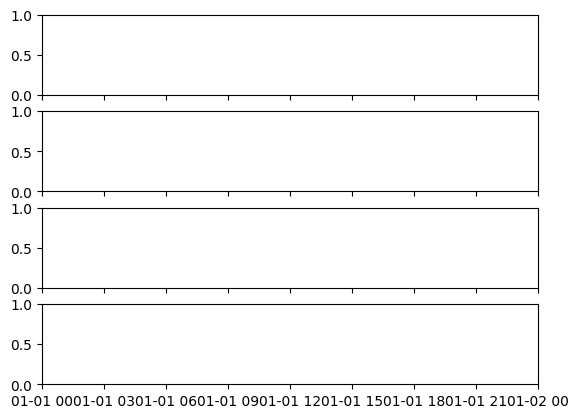

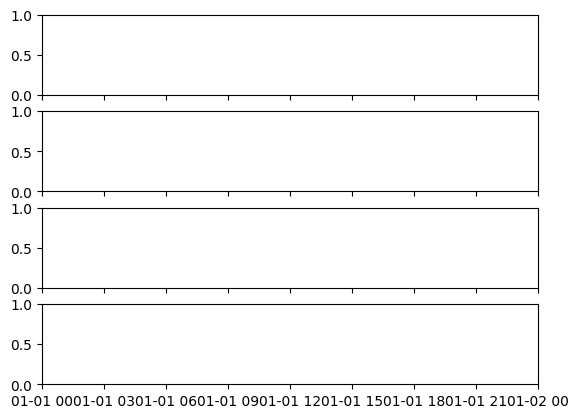

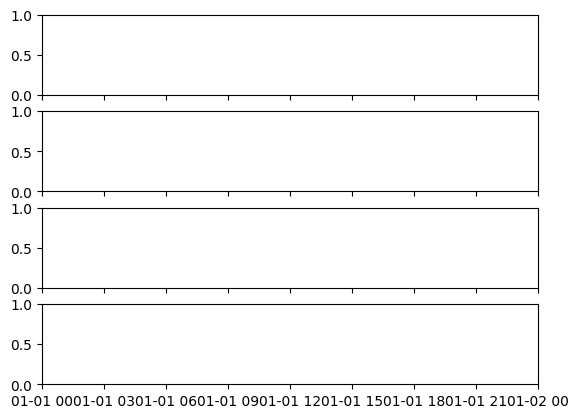

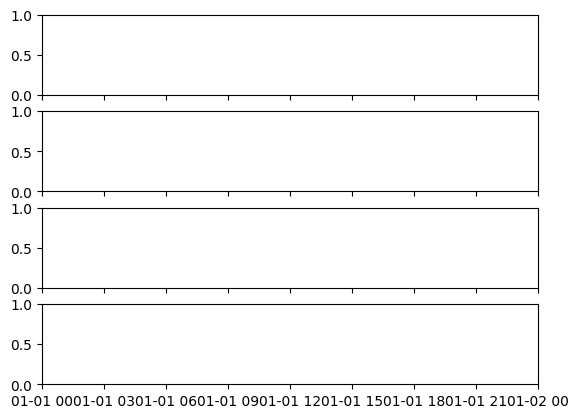

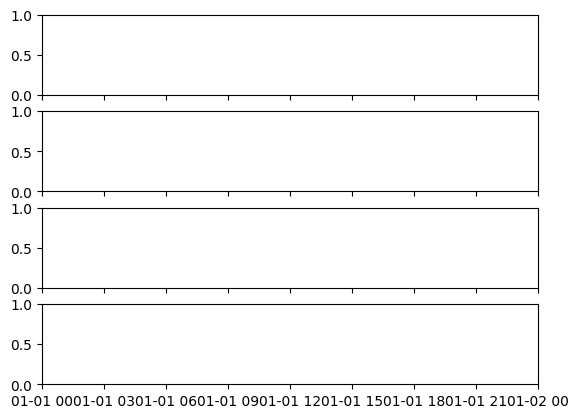

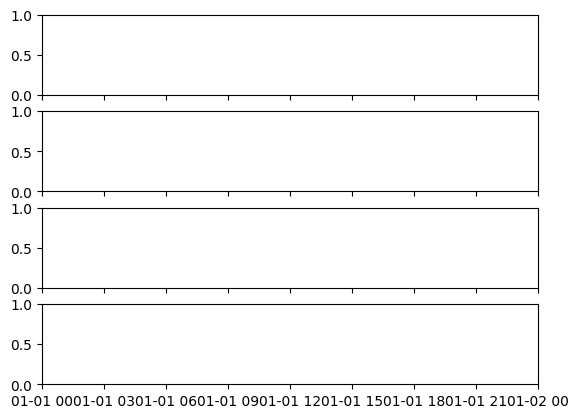

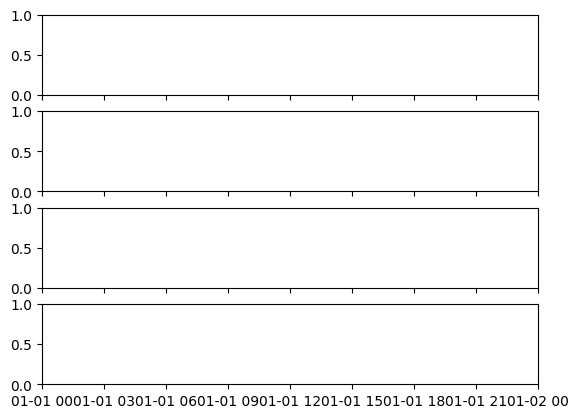

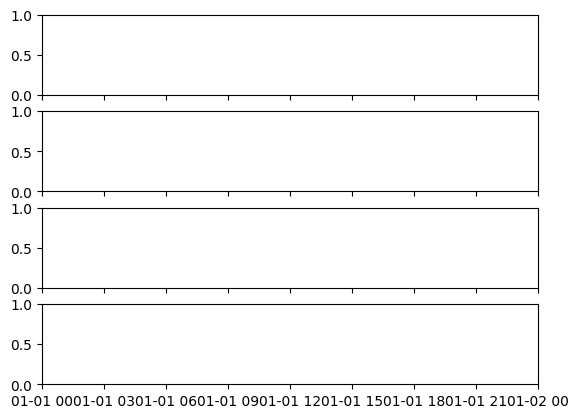

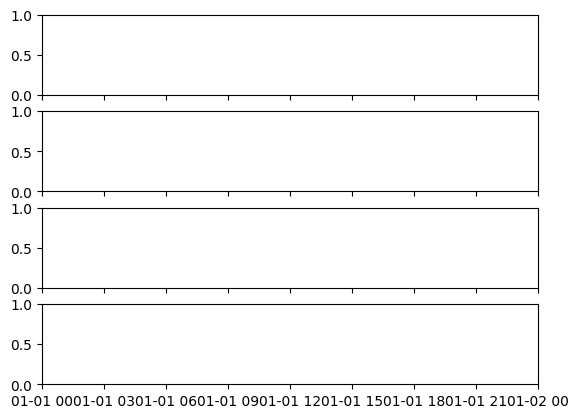

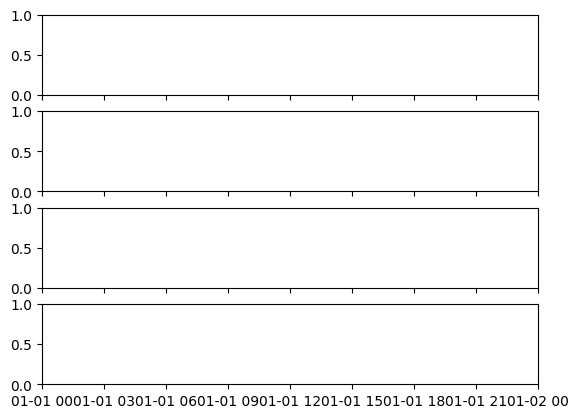

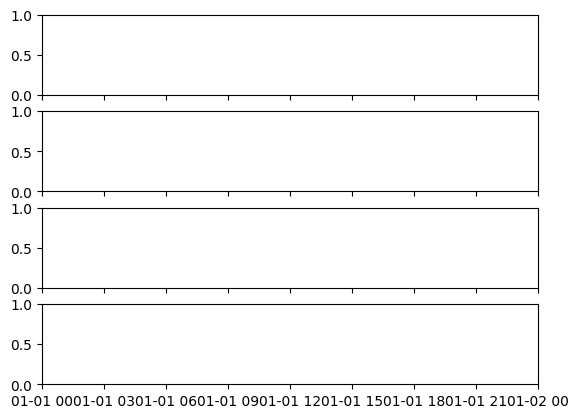

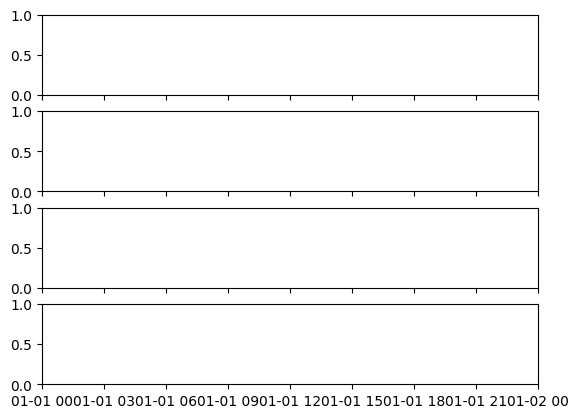

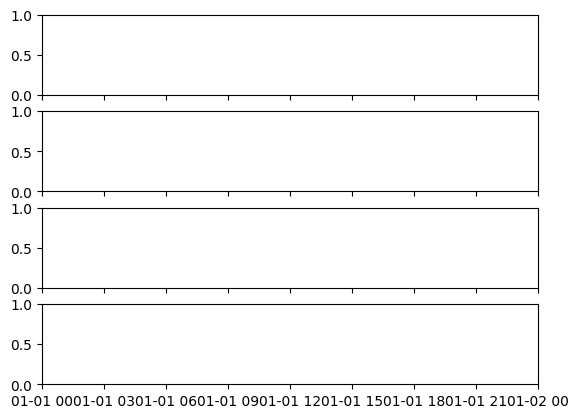

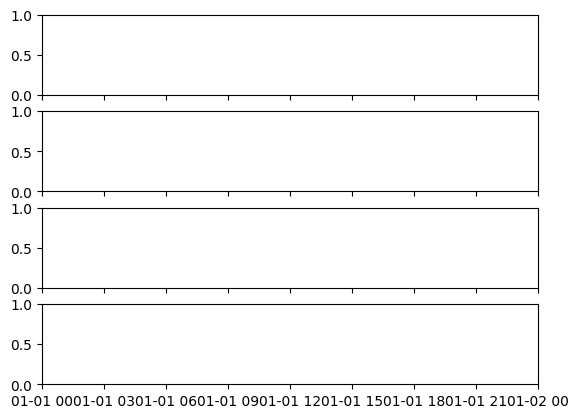

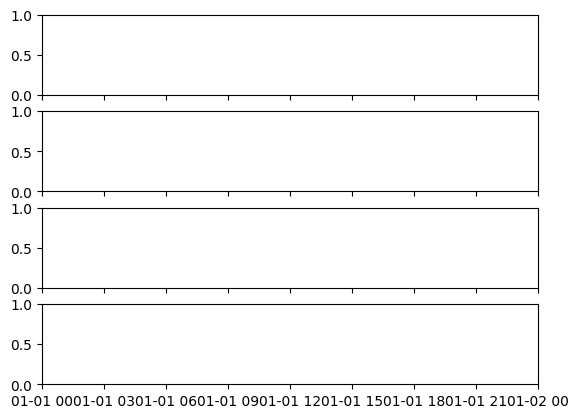

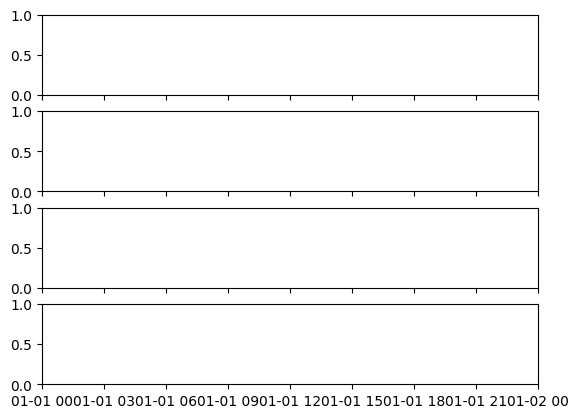

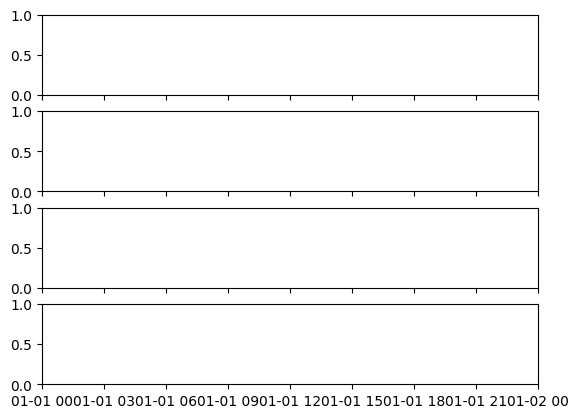

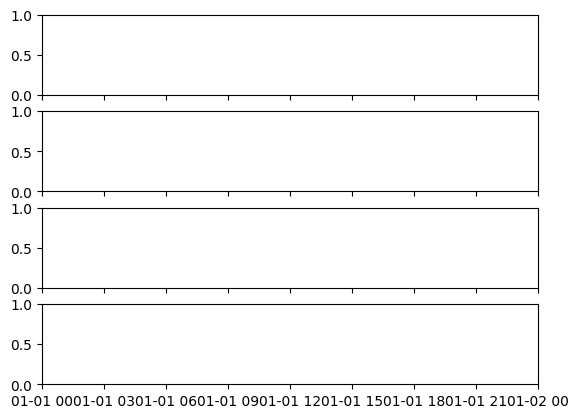

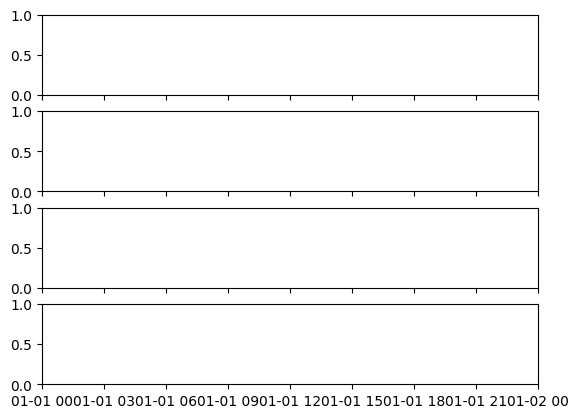

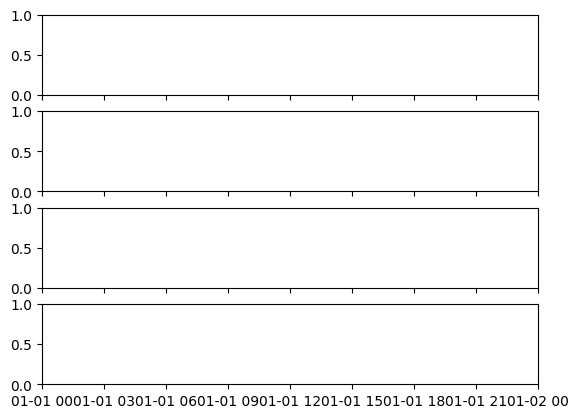

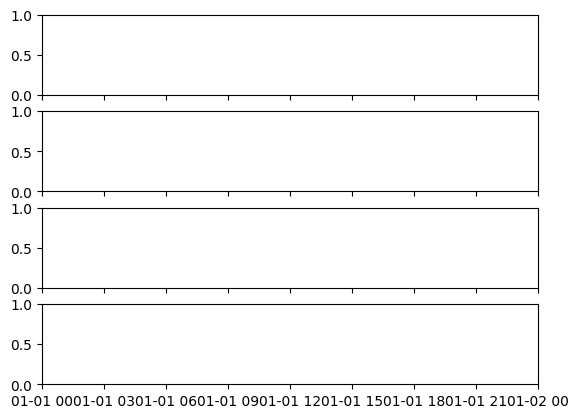

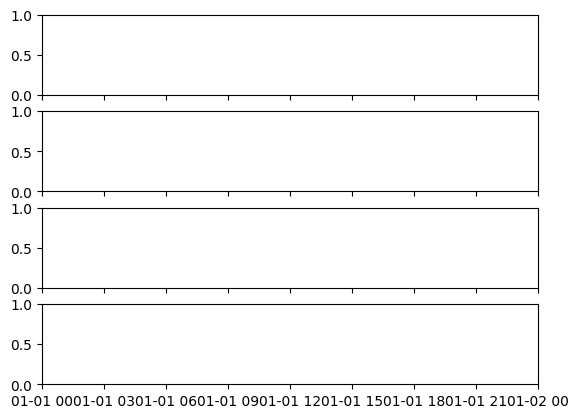

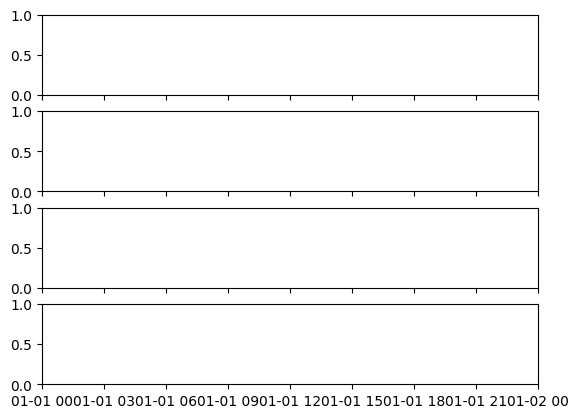

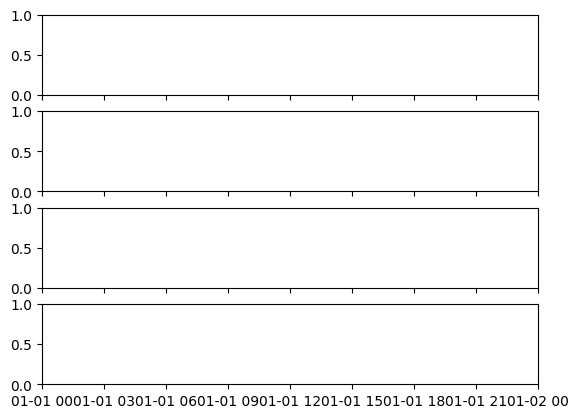

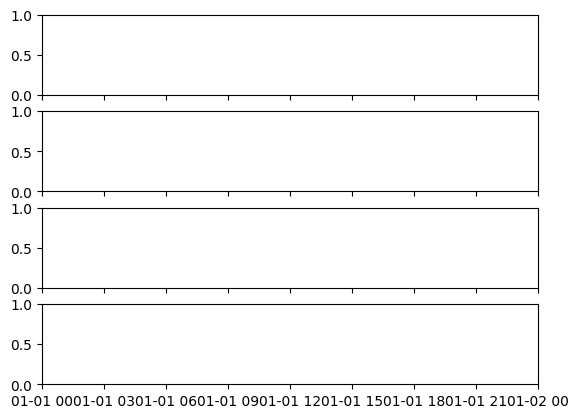

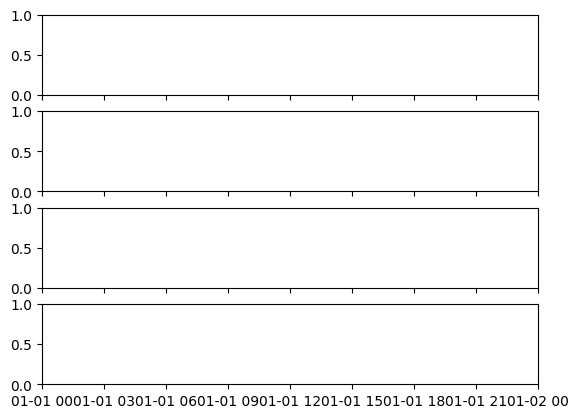

In [1]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose, STL
warnings.filterwarnings("ignore")
FILE="Water Quality.csv"; PERIOD=12; MIN_POINTS=24; MAX_SERIES=30
def locate(name):
    if os.path.isfile(name): return os.path.abspath(name)
    for base in [os.getcwd(),os.path.expanduser("~/Desktop"),os.path.expanduser("~/Downloads"),os.path.expanduser("~/Documents")]:
        if os.path.isdir(base):
            for root,dirs,files in os.walk(base):
                dirs[:]=[d for d in dirs if d not in {".git","node_modules",".venv","venv","__pycache__"}]
                for f in files:
                    if f.lower()==name.lower(): return os.path.join(root,f)
    from tkinter import Tk,filedialog
    r=Tk(); r.withdraw(); r.attributes("-topmost",True); p=filedialog.askopenfilename(title="Select Water Quality CSV",filetypes=[("CSV files","*.csv")]); r.destroy()
    return p or None
path=locate(FILE)
if not path: raise FileNotFoundError("Select Water Quality.csv or update FILE.")
df=pd.read_csv(path,low_memory=False); df.columns=df.columns.str.strip()
req={"MonitoringLocationID","ActivityStartDate","CharacteristicName","ResultValue"}
if not req.issubset(df.columns): raise ValueError(f"Missing columns: {sorted(req-set(df.columns))}")
df["ActivityStartDate"]=pd.to_datetime(df["ActivityStartDate"],errors="coerce"); df["ResultValue"]=pd.to_numeric(df["ResultValue"],errors="coerce")
df=df.dropna(subset=["MonitoringLocationID","ActivityStartDate","CharacteristicName","ResultValue"]).copy()
df["YearMonth"]=df["ActivityStartDate"].dt.to_period("M")
m=df.groupby(["MonitoringLocationID","CharacteristicName","YearMonth"])["ResultValue"].median().reset_index()
out=os.path.join(os.path.dirname(path),"task3_time_series_outputs"); os.makedirs(out,exist_ok=True)
m.assign(YearMonth=m.YearMonth.astype(str)).to_csv(os.path.join(out,"monthly_time_series_data.csv"),index=False)
try:
    import pywt
    wavelet_ok=True
except ImportError:
    wavelet_ok=False; print("Optional wavelet step skipped. Install with: python -m pip install PyWavelets")
summary=[]; processed=0
for (loc,param),g in m.groupby(["MonitoringLocationID","CharacteristicName"]):
    s=g.set_index("YearMonth")["ResultValue"].sort_index()
    idx=pd.period_range(s.index.min(),s.index.max(),freq="M"); s=s.reindex(idx)
    observed=int(s.notna().sum())
    if observed<MIN_POINTS:
        summary.append({"MonitoringLocationID":loc,"CharacteristicName":param,"ObservedMonths":observed,"Status":f"Skipped: fewer than {MIN_POINTS} observations"}); continue
    s=s.interpolate(method="linear",limit_area="inside").ffill().bfill()
    clean=lambda x: "".join(c if c.isalnum() or c in "-_" else "_" for c in str(x))[:35]
    stem=clean(loc)+"_"+clean(param); processed+=1
    try:
        d=seasonal_decompose(s.astype(float),model="additive",period=PERIOD,extrapolate_trend="freq")
        pd.DataFrame({"Month":idx.astype(str),"Observed":s.values,"Trend":d.trend.values,"Seasonal":d.seasonal.values,"Residual":d.resid.values}).to_csv(os.path.join(out,"classical_"+stem+".csv"),index=False)
    except Exception as e: print("Classical decomposition skipped:",stem,e)
    try:
        fit=STL(s.astype(float),period=PERIOD,robust=True).fit()
        pd.DataFrame({"Month":idx.astype(str),"Observed":s.values,"Trend":fit.trend,"Seasonal":fit.seasonal,"Residual":fit.resid}).to_csv(os.path.join(out,"stl_"+stem+".csv"),index=False)
        fig=fit.plot(); fig.set_size_inches(11,7); fig.suptitle(f"STL: {loc} | {param}",y=1.02); fig.tight_layout()
        fig.savefig(os.path.join(out,"stl_plot_"+stem+".png"),dpi=130,bbox_inches="tight"); plt.close(fig)
    except Exception as e: print("STL skipped:",stem,e)
    if wavelet_ok:
        try:
            vals=s.to_numpy(float); w="db4"; lev=pywt.dwt_max_level(len(vals),pywt.Wavelet(w).dec_len)
            if lev>=1:
                co=pywt.wavedec(vals,w,level=min(lev,4))
                pd.DataFrame([{"CoefficientGroup":"Approximation" if i==0 else f"Detail_Level_{len(co)-i}","CoefficientCount":len(c),"Coefficients":";".join(f"{v:.8g}" for v in c)} for i,c in enumerate(co)]).to_csv(os.path.join(out,"wavelet_"+stem+".csv"),index=False)
        except Exception as e: print("Wavelet skipped:",stem,e)
    summary.append({"MonitoringLocationID":loc,"CharacteristicName":param,"ObservedMonths":observed,"TotalMonths":len(s),"Status":"Processed"})
    if processed>=MAX_SERIES:
        print(f"Stopped at MAX_SERIES={MAX_SERIES}; increase it to process more."); break
pd.DataFrame(summary).to_csv(os.path.join(out,"decomposition_summary.csv"),index=False)
print("Task 3 outputs:",out,"| processed series:",processed)
print("Monthly medians may combine different samples. Interpolated months are estimates, not observations.")
